# Newton's method

In [12]:
import casadi as ca
import numpy as np
import matplotlib.pyplot as plt

from solvers.newton_damped import newton_damped

# Results storage for summary
optimization_results = []


# Helper function to record results
def record_result(example_name, x_g, l_g, post_proc, x_initial, m_g=None):
    """Record optimization result for summary"""
    result = {
        "example": example_name,
        "initial_guess": x_initial.flatten(),
        "iterations": len(post_proc["step"]),
        "solution": x_g.flatten(),
        "kkt_violation": post_proc["kkt_violation"][-1],
    }
    result["equality_multiplier"] = l_g.flatten()
    if m_g is not None:
        result["inequality_multiplier"] = m_g.flatten()
    optimization_results.append(result)

## Newton solver

The solver is implemented in `solvers/newton_damped.py` and solves
$$\min_x \; f(x) \quad \text{s.t.} \quad g(x) = 0$$
by applying Newton's method to the KKT conditions $\nabla_x L = 0$, $g = 0$, with $L = f + \lambda^\top g$. At each iteration:

- **Hessian**: $B = \nabla^2_{xx} L$ (`hessian="exact"`), or the Gauss-Newton approximation $B = \nabla R \nabla R^\top$ for a cost $f = \frac{1}{2}\|R(x)\|^2$ (`hessian="gauss-newton"`, residual passed as `R`).
- **Hessian regularization**: eigenvalue modification on the null space $Z$ of $\nabla g^\top$, so that $Z^\top B Z \succ 0$ and the Newton direction is a descent direction.
- **Newton direction**: solve the KKT system
  $$\begin{bmatrix} B & \nabla g \\ \nabla g^\top & 0 \end{bmatrix} \begin{bmatrix} \Delta x \\ \lambda^+ \end{bmatrix} = -\begin{bmatrix} \nabla f \\ g \end{bmatrix}.$$
  The right-hand side contains $\nabla f$ (not $\nabla_x L$), so the system gives directly the new multiplier $\lambda^+$.
- **Line search**: Armijo backtracking on the $\ell_1$ merit function $M_1(x) = f(x) + \sigma \|g(x)\|_1$, with $\sigma > \|\lambda^+\|_\infty$ (exact merit function), updated at each iteration starting from $\sigma = 0$.
- **Step**: $x \leftarrow x + \alpha \Delta x$, $\quad \lambda \leftarrow (1 - \alpha)\lambda + \alpha \lambda^+$.

The solver stops when the KKT violation $\|(\nabla_x L, g)\|_\infty$ is below tol, or when the line search fails.

## Plot function

In [13]:
def plot_contour_and_kkt(post_proc, f, g, x_g, h=None):
    fig = plt.figure(figsize=(12, 10))

    # Contour plot in the (x1, x2) plane: only for problems with 2 variables
    if x_g.shape[0] == 2:
        x1 = np.linspace(-3, 3, 100)
        x2 = np.linspace(-3, 3, 100)
        X1, X2 = np.meshgrid(x1, x2)

        # Evaluate functions on mesh
        F = np.zeros_like(X1)
        G = np.zeros_like(X1)
        if h is not None:
            H = np.zeros_like(X1)
        for i in range(X1.shape[0]):
            for j in range(X1.shape[1]):
                x_val = np.array([[X1[i, j]], [X2[i, j]]])
                F[i, j] = float(f(x_val))
                G[i, j] = float(g(x_val))
                if h is not None:
                    H[i, j] = float(h(x_val))

        # x1, x2 contour of f and g=0
        ax = fig.add_subplot(221)
        ax.contour(X1, X2, F, levels=50, cmap="viridis")
        ax.contour(X1, X2, G, levels=[0], colors="red", linewidths=2)
        if h is not None:
            ax.contour(X1, X2, H, levels=[0], colors="blue", linewidths=2)
            # Plot the area where h(x) < 0
            ax.contourf(X1, X2, H, levels=[-np.inf, 0], colors="blue", alpha=0.3)

        x_hist_array = np.array(post_proc["x"])
        ax.plot(
            x_hist_array[:, 0],
            x_hist_array[:, 1],
            "k-o",
            label="Iterations",
            linewidth=2,
            markersize=4,
        )
        ax.plot(x_g[0], x_g[1], "ro", label="Optimal Point", markersize=8)
        ax.set_title("Contour of f(x) and g(x)=0")
        ax.set_xlabel("x1")
        ax.set_ylabel("x2")
        ax.legend()
        ax.set_aspect("equal", adjustable="box")
        ax.grid()

    # KKT violation plot
    ax = fig.add_subplot(222)
    ax.semilogy(post_proc["kkt_violation"], "b-o", linewidth=2, markersize=4)
    ax.set_title("KKT Violation over Iterations")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("KKT Violation")
    ax.grid()

    # alpha plot
    ax = fig.add_subplot(223)
    ax.plot(post_proc["step"], post_proc["alpha"], "m-o", linewidth=2, markersize=4)
    ax.set_title("Step Size (alpha) over Iterations")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Alpha")
    ax.grid()

    # Objective function value plot
    ax = fig.add_subplot(224)
    f_values = [float(f(x.reshape(-1, 1))) for x in post_proc["x"]]
    ax.plot(post_proc["step"], f_values[1:], "g-o", linewidth=2, markersize=4)
    ax.set_title("Objective Function over Iterations")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("f(x)")
    ax.grid()

    plt.tight_layout()
    return fig

## Test on a strictly convex QP

For a strictly convex QP with linear equality constraints, the KKT conditions are linear: Newton's method must converge in **one full step** ($\alpha = 1$).

In [14]:
x = ca.SX.sym("x", 2)
Q = np.array([[2.0, 1.0], [1.0, 3.0]])
f_qp = ca.Function("f", [x], [0.5 * x.T @ Q @ x + x[0]])
g_qp = ca.Function("g", [x], [x[0] + x[1] - 1])

x_qp, l_qp, post_proc = newton_damped(
    f_qp, g_qp, np.array([[5.0], [5.0]]), np.array([[0.0]]), tol=1e-8
)


 Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
    1 |     1.333333 |    8.882e-16 |       8.882e-16 |   1.000000 |        [3.3333e-01, 6.6667e-01] |       [-2.3333e+00]
Converged after 1 iterations with KKT violation = 8.882e-16



## Example 1

$$\min_x \; x^\top x + \mathbf{1}^\top x \quad \text{s.t.} \quad x^\top x = 1$$

On the circle $f = 1 + x_1 + x_2$, so:
- the **minimum** is $x^* = -\tfrac{1}{\sqrt{2}}(1, 1)$, with $f^* = 1 - \sqrt{2} \approx -0.414$ and $\lambda^* = \tfrac{1}{\sqrt{2}} - 1 \approx -0.293$;
- the **maximum** is $\bar{x} = \tfrac{1}{\sqrt{2}}(1, 1)$, with $\bar{\lambda} = -\tfrac{1}{\sqrt{2}} - 1 \approx -1.707$.

Both are KKT points. Since $\nabla^2_{xx} L = 2(1 + \lambda) I$, SOSC holds at $x^*$ ($2(1 + \lambda^*) \approx 1.41 > 0$) and fails at $\bar{x}$ ($\approx -1.41$).

In [15]:
nx = 2
x = ca.SX.sym("x", nx)

_f = x.T @ x + ca.SX.ones(nx).T @ x
f = ca.Function("f", [x], [_f])

_g = x.T @ x - 1
g = ca.Function("g", [x], [_g])

### Initial guesses $(0, 1)$, $(-1, -1)$, $(-1, 1)$


 Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
    1 |     1.812500 |    6.250e-02 |       1.500e+00 |   0.500000 |       [-2.5000e-01, 1.0000e+00] |       [-7.5000e-01]
    2 |     1.526209 |    1.466e-01 |       1.324e+00 |   0.125000 |       [-5.4320e-01, 9.2279e-01] |       [-8.2445e-01]
    3 |     1.075194 |    3.659e-01 |       1.179e+00 |   0.125000 |       [-9.5890e-01, 6.6816e-01] |       [-8.6568e-01]
    4 |     0.708848 |    4.481e-01 |       1.106e+00 |   0.062500 |       [-1.1360e+00, 3.9683e-01] |       [-8.6630e-01]
    5 |     0.397511 |    5.088e-01 |       1.032e+00 |   0.062500 |       [-1.2232e+00, 1.1191e-01] |       [-8.5741e-01]
    6 |     0.067131 |    6.729e-01 |       8.732e-01 |   0.125000 |      [-1.2409e+00, -3.6490e-01] |       [-8.2619e-01]
    7 |    -0.081182 |    6.492e-01 |       7.449e-01 |   0.125000 |      [-1.1410e+00, -5.8937e-01] |       [-7.8356e-01]
    8 |    -0.1

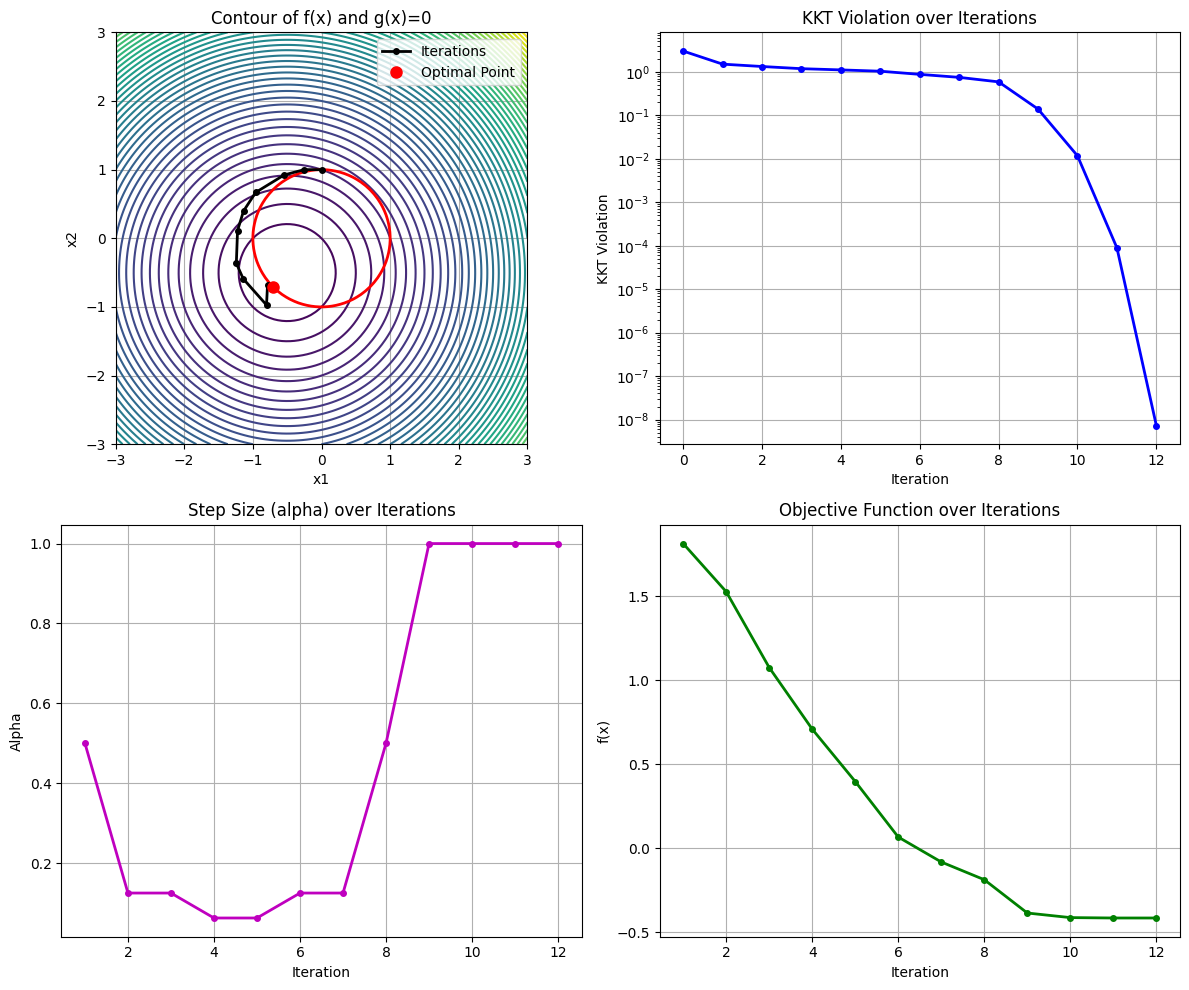

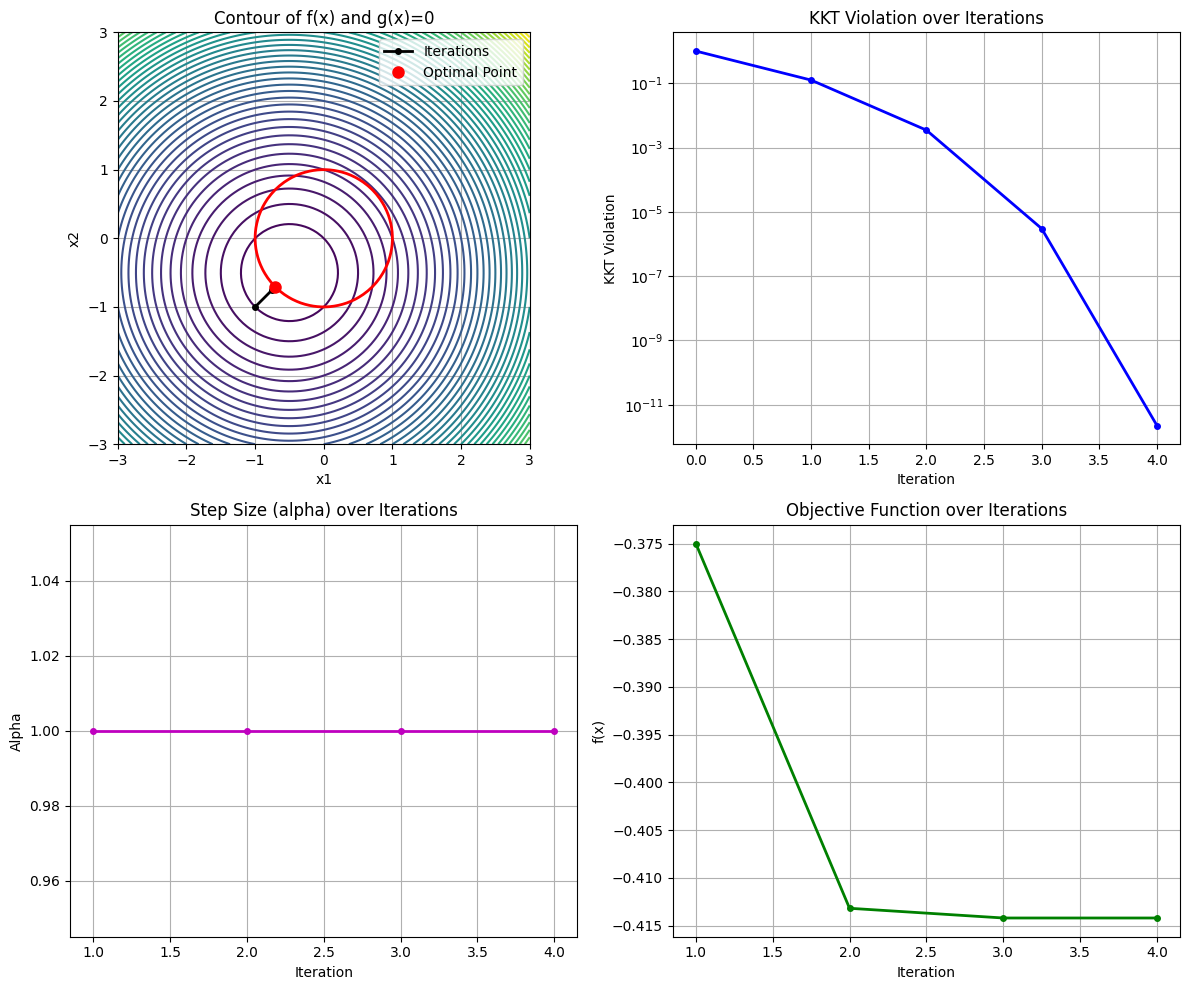

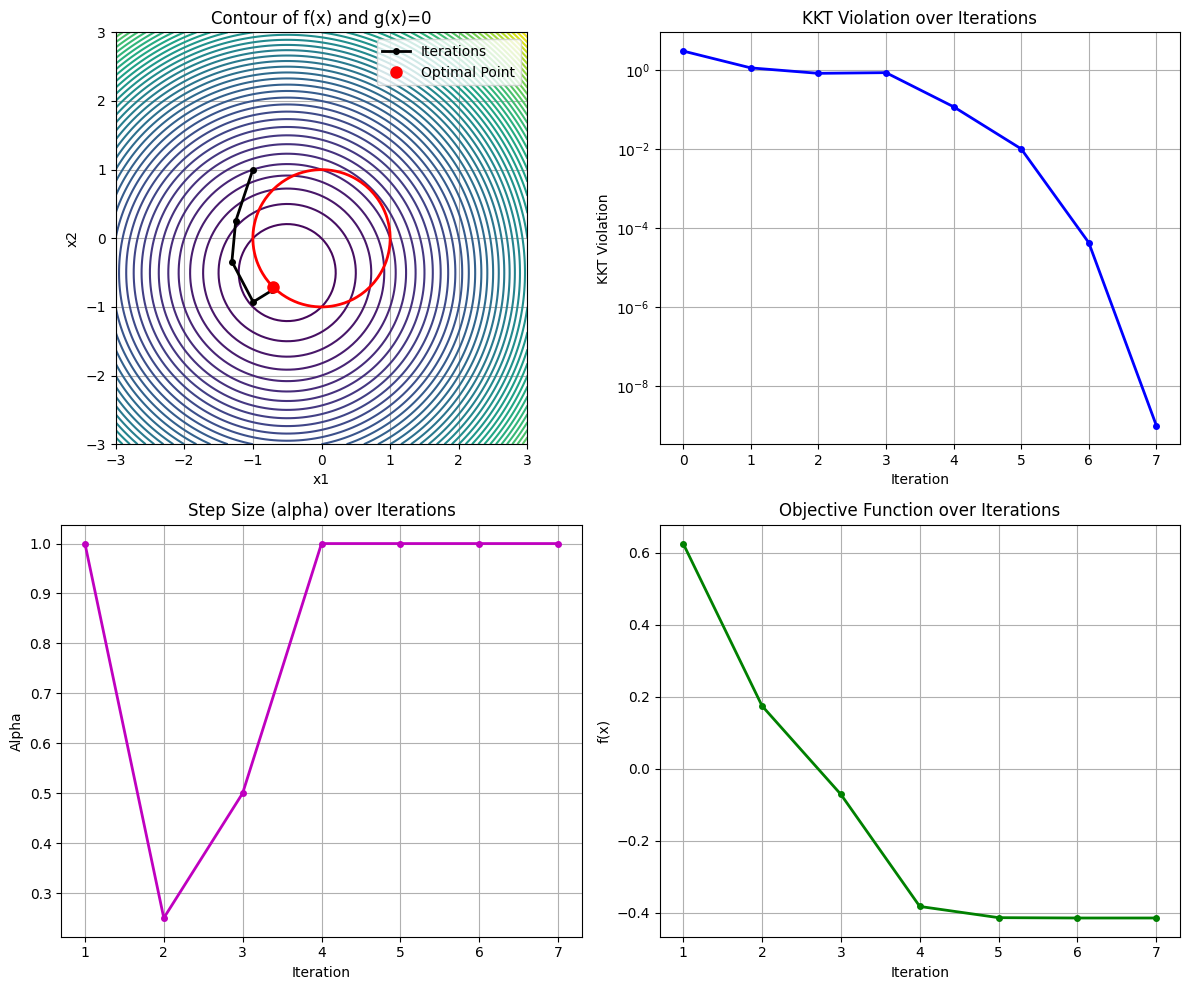

In [16]:
# 1
x_g = np.array([[0.0], [1.0]])
l_g = np.array([[0.0]])
x_init = x_g.copy()

try:
    x_g, l_g, post_proc = newton_damped(
        f, g, x_g, l_g, beta=0.5, gamma=0.1, sigma=0, tol=1e-8
    )
    record_result("Example 1", x_g, l_g, post_proc, x_init)
    fig = plot_contour_and_kkt(post_proc, f, g, x_g)
except Exception as e:
    print("Error during optimization:", e)

# 2
x_g = np.array([[-1.0], [-1.0]])
l_g = np.array([[0.0]])
x_init = x_g.copy()

try:
    x_g, l_g, post_proc = newton_damped(
        f, g, x_g, l_g, beta=0.5, gamma=0.1, sigma=0, tol=1e-8
    )
    record_result("Example 1", x_g, l_g, post_proc, x_init)
    fig = plot_contour_and_kkt(post_proc, f, g, x_g)
except Exception as e:
    print("Error during optimization:", e)

# 3
x_g = np.array([[-1.0], [1.0]])
l_g = np.array([[0.0]])
x_init = x_g.copy()

try:
    x_g, l_g, post_proc = newton_damped(
        f, g, x_g, l_g, beta=0.5, gamma=0.1, sigma=0, tol=1e-8
    )
    record_result("Example 1", x_g, l_g, post_proc, x_init)
    fig = plot_contour_and_kkt(post_proc, f, g, x_g)
except Exception as e:
    print("Error during optimization:", e)

**Observations.** All three initial guesses converge to the minimum $x^*$. From $(-1, -1)$ the full step $\alpha = 1$ is always accepted (4 iterations). From $(0, 1)$ and $(-1, 1)$ the iterates start far from $x^*$ and some of the first steps are damped ($\alpha < 1$): from $(0, 1)$ the first 8, from $(-1, 1)$ the 2nd and the 3rd; once close to $x^*$, full steps are accepted and the KKT violation decreases quadratically (e.g. from $(0, 1)$: $1.2 \cdot 10^{-2} \to 9.0 \cdot 10^{-5} \to 7.3 \cdot 10^{-9}$).

### Initial guesses $(1, 1)$ and $(1, 1 + 10^{-6})$


 Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
    1 |     2.625000 |    1.250e-01 |       6.250e-01 |   1.000000 |        [7.5000e-01, 7.5000e-01] |       [-1.2500e+00]
    2 |     2.420139 |    3.472e-03 |       3.588e-02 |   1.000000 |        [7.0833e-01, 7.0833e-01] |       [-1.6806e+00]
    3 |     2.414219 |    3.004e-06 |       6.496e-05 |   1.000000 |        [7.0711e-01, 7.0711e-01] |       [-1.7071e+00]
    4 |     2.414214 |    2.255e-12 |       9.982e-11 |   1.000000 |        [7.0711e-01, 7.0711e-01] |       [-1.7071e+00]
Converged after 4 iterations with KKT violation = 9.982e-11


 Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
    1 |     2.625001 |    1.250e-01 |       6.250e-01 |   1.000000 |        [7.5000e-01, 7.5000e-01] |       [-1.2500e+00]
    2 |     2.420139 |    3.472e-03 |       3.588e-02 |   1.000000 |        

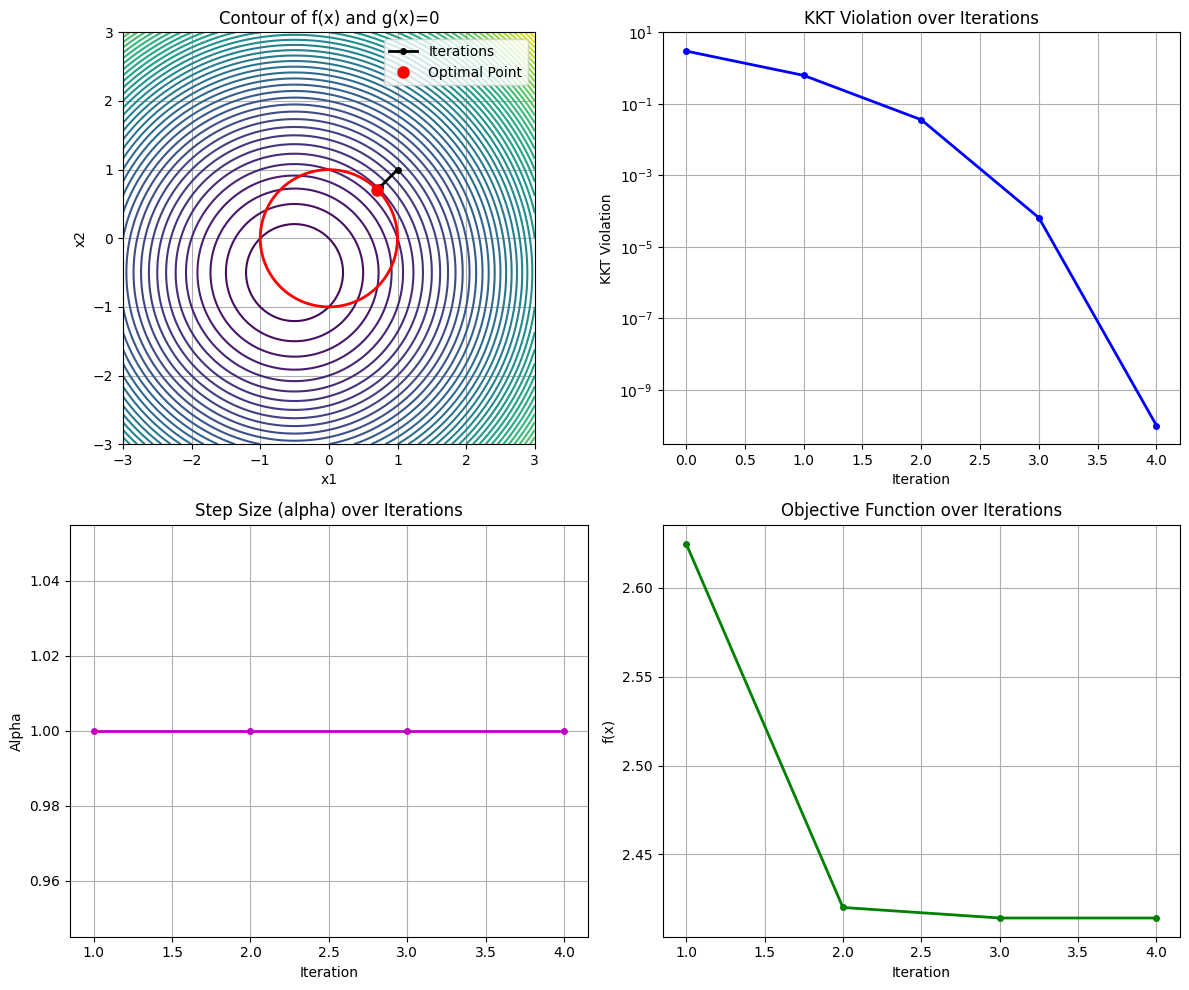

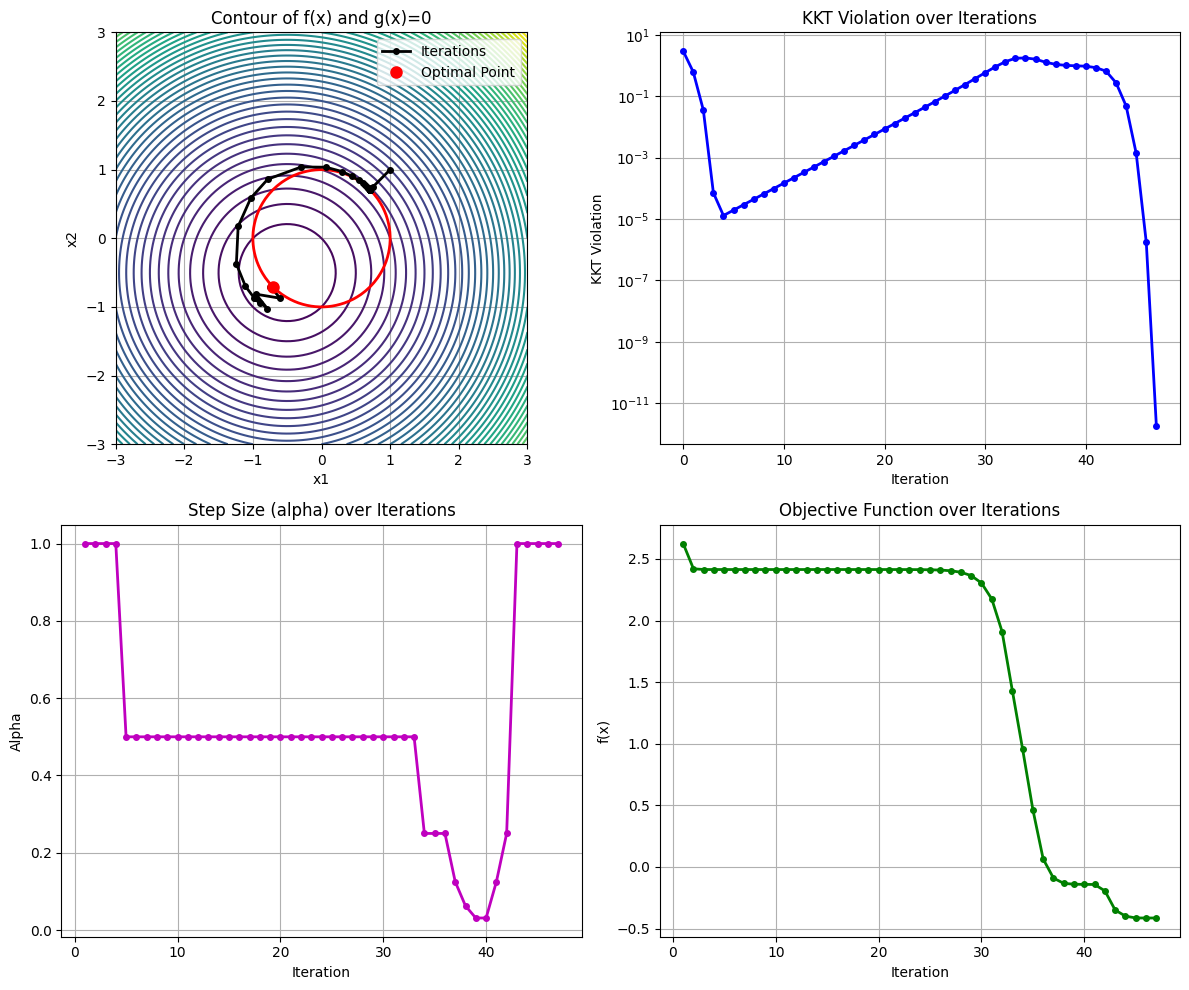

In [17]:
# 1
x_g = np.array([[1.0], [1.0]])
l_g = np.array([[0.0]])
x_init = x_g.copy()

try:
    x_g, l_g, post_proc = newton_damped(
        f, g, x_g, l_g, beta=0.5, gamma=0.1, sigma=0, tol=1e-8
    )
    record_result("Example 1", x_g, l_g, post_proc, x_init)
    fig = plot_contour_and_kkt(post_proc, f, g, x_g)
except Exception as e:
    print("Error during optimization:", e)

# 2
x_g = np.array([[1.0], [1.0 + 1e-6]])
l_g = np.array([[0.0]])
x_init = x_g.copy()

try:
    x_g, l_g, post_proc = newton_damped(
        f, g, x_g, l_g, beta=0.5, gamma=0.1, sigma=0, tol=1e-8
    )
    record_result("Example 1", x_g, l_g, post_proc, x_init)
    fig = plot_contour_and_kkt(post_proc, f, g, x_g)
except Exception as e:
    print("Error during optimization:", e)

**Observations.** From $(1, 1)$ the method converges in 4 iterations to $\bar{x} = \tfrac{1}{\sqrt{2}}(1, 1)$, the **maximum** of $f$ on the circle: a KKT point that does not satisfy SOSC.

The reason is symmetry. On the diagonal $x_1 = x_2$, both $\nabla f = 2x + \mathbf{1}$ and $\nabla g = 2x$ are parallel to $(1, 1)$, so the Newton step stays on the diagonal. The Hessian regularization only acts on the null space of $\nabla g^\top$, i.e. along $(1, -1)$, where the step has no component: it cannot push the iterates away from $\bar{x}$.

With $x_2 = 1 + 10^{-6}$ the symmetry is broken. Thanks to the regularization the maximum is repulsive: $|x_1 - x_2|$ grows from $10^{-6}$ to $10^{-2}$ in 20 iterations, then the iterates slide along the circle and converge to $x^*$ (47 iterations, most of them damped). Without regularization, the method would converge to the maximum $\bar{x}$ also from this initial guess.

### Initial guess $(0, 0)$

In [18]:
x_g = np.array([[0.0], [0.0]])
l_g = np.array([[0.0]])
x_init = x_g.copy()

try:
    x_g, l_g, post_proc = newton_damped(
        f, g, x_g, l_g, beta=0.5, gamma=0.1, sigma=0, tol=1e-8
    )
    record_result("Example 1", x_g, l_g, post_proc, x_init)
    fig = plot_contour_and_kkt(post_proc, f, g, x_g)
except Exception as e:
    print("Error during optimization:", e)


 Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
Error during optimization: KKT matrix is singular at x = [0. 0.]: is LICQ satisfied?


**Observations.** At $x = (0, 0)$ we have $\nabla g(x) = 2x = 0$: **LICQ fails** at the initial guess. The KKT matrix $\begin{bmatrix} B & \nabla g \\ \nabla g^\top & 0 \end{bmatrix}$ has a zero row and column, so it is singular and the Newton step is not defined. Equivalently, the linearized constraint $g(x) + \nabla g(x)^\top \Delta x = -1 = 0$ has no solution.

### Initial guess $(0.5, 1)$


 Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
    1 |     2.312500 |    6.250e-02 |       7.500e-01 |   1.000000 |        [2.5000e-01, 1.0000e+00] |       [-1.5000e+00]
    2 |     2.188477 |    8.002e-02 |       9.246e-01 |   0.250000 |        [7.1691e-02, 1.0368e+00] |       [-1.5257e+00]
    3 |     2.002011 |    1.089e-01 |       1.157e+00 |   0.250000 |       [-1.4924e-01, 1.0424e+00] |       [-1.5275e+00]
    4 |     1.732444 |    1.537e-01 |       1.415e+00 |   0.250000 |       [-4.1288e-01, 9.9159e-01] |       [-1.5028e+00]
    5 |     1.365294 |    2.213e-01 |       1.633e+00 |   0.250000 |       [-7.0613e-01, 8.5011e-01] |       [-1.4481e+00]
    6 |     0.908489 |    3.209e-01 |       1.716e+00 |   0.250000 |       [-9.9229e-01, 5.7988e-01] |       [-1.3610e+00]
    7 |     0.418421 |    4.663e-01 |       1.583e+00 |   0.250000 |       [-1.2011e+00, 1.5331e-01] |       [-1.2427e+00]
    8 |     0.1

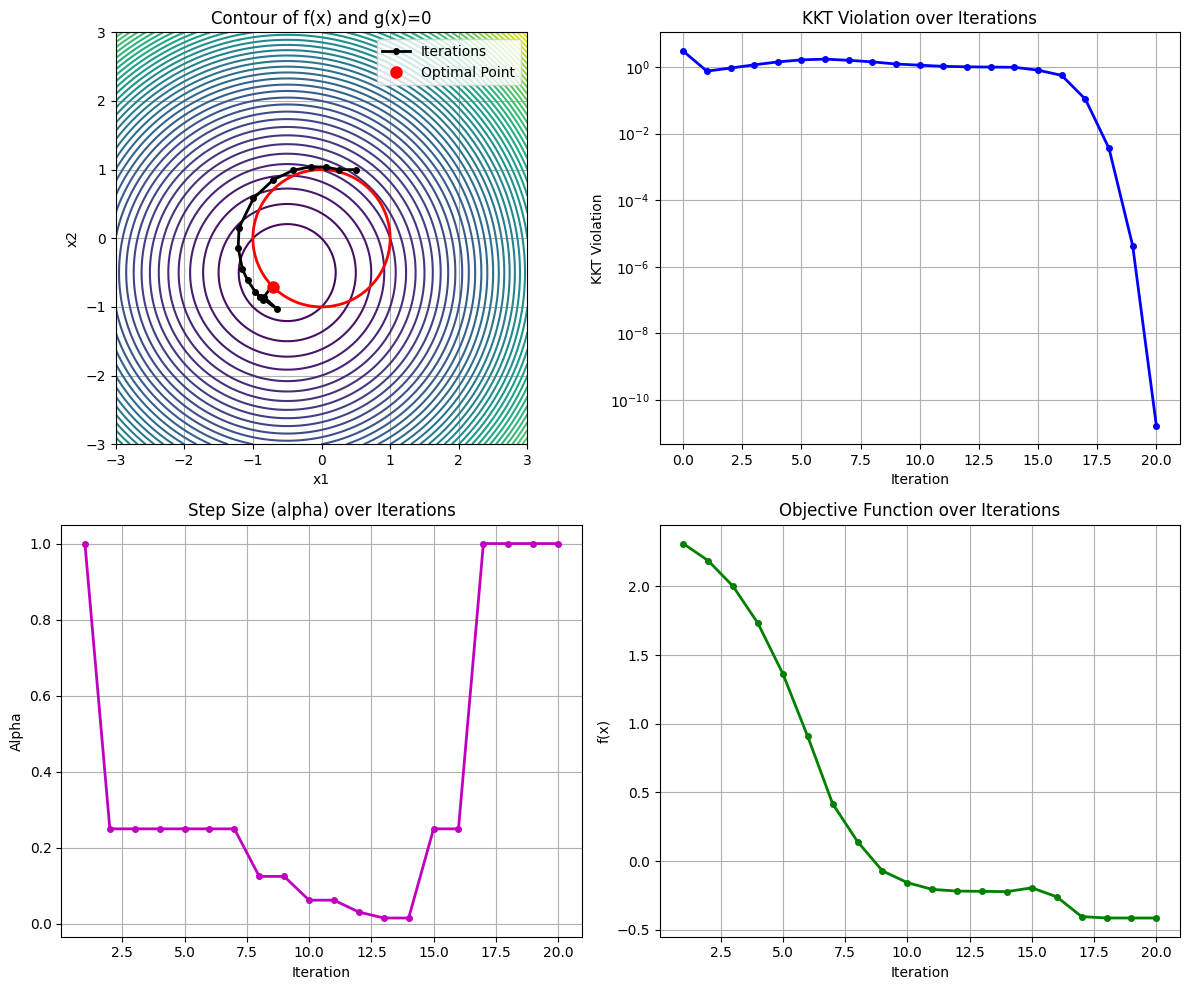

In [19]:
x_g = np.array([[0.5], [1.0]])
l_g = np.array([[0.0]])
x_init = x_g.copy()

try:
    x_g, l_g, post_proc = newton_damped(
        f, g, x_g, l_g, beta=0.5, gamma=0.1, sigma=0, tol=1e-8
    )
    record_result("Example 1", x_g, l_g, post_proc, x_init)
    fig = plot_contour_and_kkt(post_proc, f, g, x_g)
except Exception as e:
    print("Error during optimization:", e)

**Observations.** After the first step $\lambda = -1.5$, so the exact Hessian $\nabla^2_{xx} L = 2(1 + \lambda) I = -I$ is negative definite. Without regularization the Newton direction is not a descent direction for the merit function: the line search fails at the second iteration and the iterates get stuck at $(0.25, 1)$.

**Fix:** regularize the Hessian so that $Z^\top B Z \succ 0$ (eigenvalue modification), as done in `newton_damped`. Together with $\sigma > \|\lambda^+\|_\infty$, the Newton direction is then a descent direction for the $\ell_1$ merit function and the method converges to $x^*$ (20 iterations, 15 of them damped).

### Gauss-Newton Hessian

The cost is a least-squares one: $f(x) = \tfrac{1}{2} \|R(x)\|^2 - \tfrac{1}{2}$ with $R(x) = \sqrt{2}\,(x + \tfrac{1}{2}\mathbf{1})$. We compare the exact Hessian with the Gauss-Newton approximation $B = \nabla R \nabla R^\top$, starting from $(0, 1)$.


 Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
    1 |     1.812500 |    6.250e-02 |       1.500e+00 |   0.500000 |       [-2.5000e-01, 1.0000e+00] |       [-7.5000e-01]
    2 |     1.526209 |    1.466e-01 |       1.324e+00 |   0.125000 |       [-5.4320e-01, 9.2279e-01] |       [-8.2445e-01]
    3 |     1.075194 |    3.659e-01 |       1.179e+00 |   0.125000 |       [-9.5890e-01, 6.6816e-01] |       [-8.6568e-01]
    4 |     0.708848 |    4.481e-01 |       1.106e+00 |   0.062500 |       [-1.1360e+00, 3.9683e-01] |       [-8.6630e-01]
    5 |     0.397511 |    5.088e-01 |       1.032e+00 |   0.062500 |       [-1.2232e+00, 1.1191e-01] |       [-8.5741e-01]
    6 |     0.067131 |    6.729e-01 |       8.732e-01 |   0.125000 |      [-1.2409e+00, -3.6490e-01] |       [-8.2619e-01]
    7 |    -0.081182 |    6.492e-01 |       7.449e-01 |   0.125000 |      [-1.1410e+00, -5.8937e-01] |       [-7.8356e-01]
    8 |    -0.1

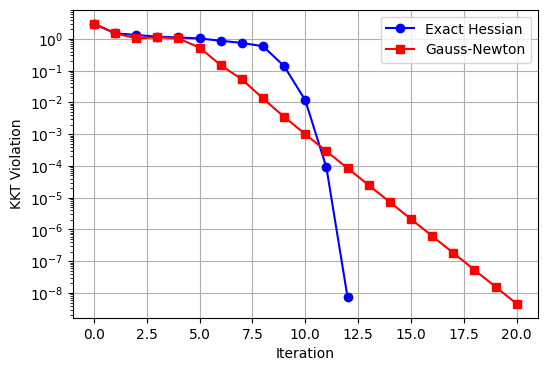

In [20]:
R = ca.Function("R", [x], [np.sqrt(2) * (x + 0.5)])
x0 = np.array([[0.0], [1.0]])

_, _, post_proc_exact = newton_damped(f, g, x0, np.array([[0.0]]), tol=1e-8)
_, _, post_proc_gn = newton_damped(
    f, g, x0, np.array([[0.0]]), tol=1e-8, hessian="gauss-newton", R=R
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(post_proc_exact["kkt_violation"], "b-o", label="Exact Hessian")
ax.semilogy(post_proc_gn["kkt_violation"], "r-s", label="Gauss-Newton")
ax.set_xlabel("Iteration")
ax.set_ylabel("KKT Violation")
ax.legend()
ax.grid()

**Observations.** $R$ is linear, so $\nabla R \nabla R^\top = 2I = \nabla^2 f$: Gauss-Newton is exact for the cost, but it neglects the curvature of the constraint, $\lambda \nabla^2 g = 2\lambda I$. The exact Hessian converges quadratically (12 iterations), Gauss-Newton only **linearly** (20 iterations), with a constant contraction rate $\approx 0.29 = |\lambda^*|$: the relative error of the Hessian approximation at the solution, $|2 - 2(1 + \lambda^*)| / 2$. The approximation is good when the multipliers are small.

## Example 2


 Step |         f(x) |         g(x) |   KKT Violation |  Step Size |                               x |                   λ
    1 |     0.651598 |   -3.690e-02 |       1.519e+00 |   1.000000 | [-3.0120e-01, 3.9960e-01, -3... | [3.0120e-01, 3.0...
    2 |     0.073409 |    9.504e-02 |       1.623e+00 |   1.000000 | [3.0825e-01, -2.2104e-02, 2.... | [1.6329e+00, 1.6...
    3 |    -0.217238 |    1.622e-01 |       4.057e-01 |   1.000000 | [1.5224e-01, -4.1115e-01, 4.... | [3.3253e-01, 3.2...
    4 |    -0.210216 |    5.709e-02 |       7.786e-02 |   1.000000 | [-2.5083e-02, -3.0448e-01, 3... | [5.5208e-01, 5.4...
    5 |    -0.162579 |    1.752e-02 |       2.280e-01 |   1.000000 | [1.3887e-02, -2.0537e-01, 2.... | [1.4114e+00, 1.4...
    6 |    -0.142292 |    1.022e-02 |       1.925e-01 |   0.500000 | [2.0671e-04, -1.7226e-01, 1.... | [2.5811e+00, 2.5...
    7 |    -0.101522 |    3.029e-03 |       2.905e-01 |   1.000000 | [-1.9932e-04, -1.1484e-01, 1... | [6.0343e+00, 6.0...
    8 |    -0.0

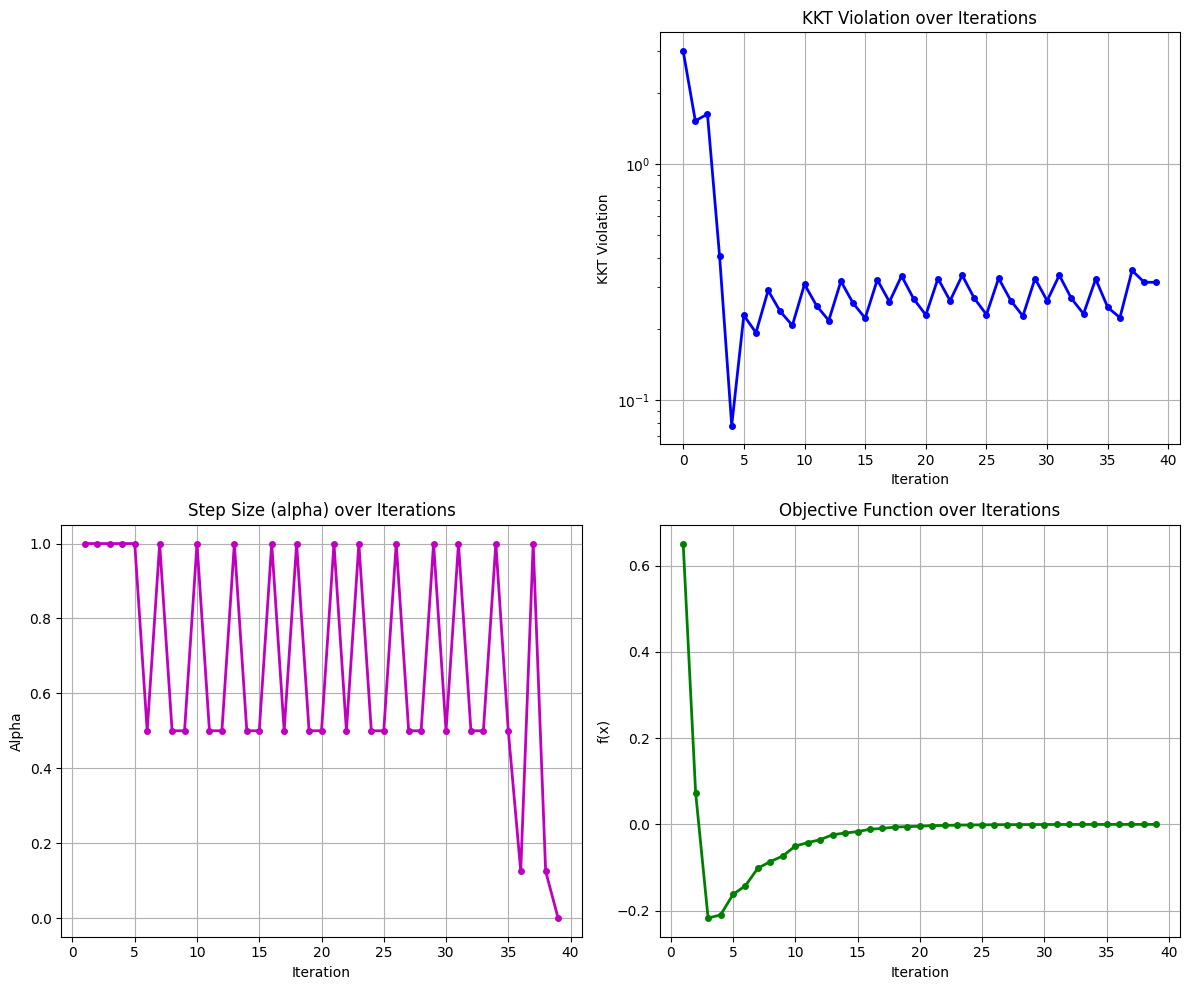

In [21]:
nx = 3
x = ca.SX.sym("x", nx)

_f = x.T @ x + x[1]
f = ca.Function("f", [x], [_f])

_g1 = x[0] ** 2 - 2 * x[1] ** 3 - x[1] - 10 * x[2]
_g2 = x[1] + 10 * x[2]
g = ca.Function("g", [x], [ca.vertcat(_g1, _g2)])

x_g = np.array([[1.0], [1.0], [0.0]])
l_g = np.array([[0.0], [0.0]])
x_init = x_g.copy()

try:
    x_g, l_g, post_proc = newton_damped(
        f, g, x_g, l_g, beta=0.5, gamma=0.1, sigma=0, tol=1e-9
    )
    record_result("Example 2", x_g, l_g, post_proc, x_init)
    print("Optimal x:", x_g.flatten())
    print("Optimal λ:", l_g.flatten())
    fig = plot_contour_and_kkt(post_proc, f, g, x_g)
except Exception as e:
    print("Error during optimization:", e)

# Solve the problem with IPOPT for comparison
try:
    nlp = {"x": x, "f": f(x), "g": g(x)}
    solver = ca.nlpsol("solver", "ipopt", nlp)
    sol = solver(x0=x_init, lbg=0.0, ubg=0.0)
    x_opt_ipopt = sol["x"].full()
    print("Optimal x (IPOPT):", x_opt_ipopt.flatten())
except Exception as e:
    print("Error during IPOPT optimization:", e)

**Observations.** Newton's method does not converge: $x \to 0$, but the multipliers grow without bound (about two orders of magnitude every 8 iterations, $\|\lambda\|_\infty \approx 5 \cdot 10^7$ at the end), the KKT violation stalls and the line search fails at iteration 40.

From $g_2 = 0$ we get $x_2 = -10 x_3$, and substituting in $g_1 = 0$: $x_1^2 = 2 x_2^3$, i.e. $x_2 \ge 0$ on the feasible set. Then $f = x_1^2 + x_2^2 + x_3^2 + x_2 \ge 0$, with equality only at $x^* = 0$: this is the solution.

At $x^*$, $\nabla g_1 = (0, -1, -10)$ and $\nabla g_2 = (0, 1, 10)$ are linearly dependent: **LICQ fails**. Moreover $x^*$ is **not a KKT point**: stationarity would require $(0, 1, 0) + (\lambda_2 - \lambda_1)(0, 1, 10) = 0$, which is impossible. No finite multipliers exist: Newton's method, which solves the KKT conditions, drives $\lambda \to \infty$. Since $\sigma > \|\lambda\|_\infty$, the merit function is dominated by the constraint violation and the line search eventually fails.

IPOPT, started from the same initial guess, stops at a similar point with $\lambda \approx 1.25 \cdot 10^8$. It reports success only because its stopping test scales the dual infeasibility with the size of the multipliers.

## Summary

In [22]:
def fmt(v, digits=4):
    """Format a vector with the given number of significant digits"""
    return "[" + ", ".join(f"{e:.{digits}g}" for e in v) + "]"


print(f"{'Example':>9} | {'x0':>16} | {'solution':>34} | {'lambda':>22} | {'iter':>4} | {'KKT':>9}")
print("-" * 108)
for r in optimization_results:
    print(
        f"{r['example']:>9} | {fmt(r['initial_guess'], 8):>16} | {fmt(r['solution']):>34} | "
        f"{fmt(r['equality_multiplier']):>22} | {r['iterations']:>4} | {r['kkt_violation']:>9.2e}"
    )

  Example |               x0 |                           solution |                 lambda | iter |       KKT
------------------------------------------------------------------------------------------------------------
Example 1 |           [0, 1] |                 [-0.7071, -0.7071] |              [-0.2929] |   12 |  7.33e-09
Example 1 |         [-1, -1] |                 [-0.7071, -0.7071] |              [-0.2929] |    4 |  2.26e-12
Example 1 |          [-1, 1] |                 [-0.7071, -0.7071] |              [-0.2929] |    7 |  9.97e-10
Example 1 |           [1, 1] |                   [0.7071, 0.7071] |               [-1.707] |    4 |  9.98e-11
Example 1 |    [1, 1.000001] |                 [-0.7071, -0.7071] |              [-0.2929] |   47 |  1.85e-12
Example 1 |         [0.5, 1] |                 [-0.7071, -0.7071] |              [-0.2929] |   20 |  1.73e-11
Example 2 |        [1, 1, 0] | [5.006e-28, -4.549e-05, 4.549e-06] | [5.518e+07, 5.518e+07] |   39 |  3.15e-01
